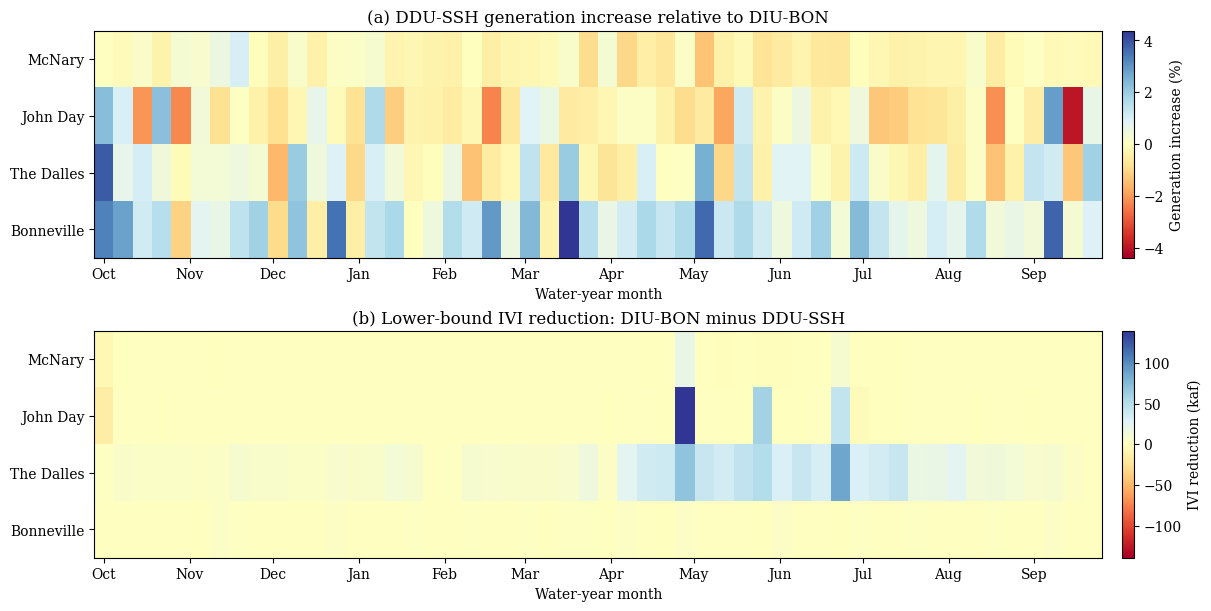

In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy.io import loadmat

# Full-year fixed-head headline results
folder = Path("/Users/elizacohn/Desktop/matlab_ddu_four_unit/results/final/paper_sigma/N8760_headline/jobs")
units = ["McNary", "John Day", "The Dalles", "Bonneville"]

def load_run(scenario, policy, method):
    kappa = 0 if policy == "DIU" else 100
    file = folder / f"s{scenario:02d}_e100_{policy}_k{kappa:03d}_{method}.mat"
    return loadmat(file, simplify_cells=True)["traj"]

def weekly_sum(x):
    # Use 52 complete weeks
    x = np.asarray(x)[:52 * 168]
    return x.reshape(52, 168, 4).sum(axis=1)

generation = []
ivi_reduction = []

for scenario in range(1, 11):
    baseline = load_run(scenario, "DIU", "BON")
    headline = load_run(scenario, "DDU", "SSH")

    base_energy = weekly_sum(baseline["power"])
    head_energy = weekly_sum(headline["power"])
    generation.append(100 * (head_energy - base_energy) / base_energy)

    base_ivi = np.maximum(baseline["qLow"] - baseline["V"], 0)
    head_ivi = np.maximum(headline["qLow"] - headline["V"], 0)
    ivi_reduction.append(weekly_sum(base_ivi) - weekly_sum(head_ivi))

# Mean across the 10 paired scenarios; transpose to project × week
generation = np.mean(generation, axis=0).T
ivi_reduction = np.mean(ivi_reduction, axis=0).T

months = ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar",
          "Apr", "May", "Jun", "Jul", "Aug", "Sep"]
month_days = np.array([0, 31, 61, 92, 123, 152, 183, 213, 244, 274, 305, 336])
month_ticks = month_days / 7

plt.rcParams.update({"font.family": "serif", "font.size": 10})
fig, axes = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)

plots = [
    (generation, "Generation increase (%)",
     "(a) DDU-SSH generation increase relative to DIU-BON"),
    (ivi_reduction, "IVI reduction (kaf)",
     "(b) Lower-bound IVI reduction: DIU-BON minus DDU-SSH")
]

for ax, (values, colorbar_label, title) in zip(axes, plots):
    limit = np.max(np.abs(values))

    image = ax.imshow(
        values,
        aspect="auto",
        cmap="RdYlBu",
        norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
    )

    ax.set_yticks(range(4), units)
    ax.set_xticks(month_ticks, months)
    ax.set_xlabel("Water-year month")
    ax.set_title(title)

    cbar = fig.colorbar(image, ax=ax, pad=0.02)
    cbar.set_label(colorbar_label)

plt.show()

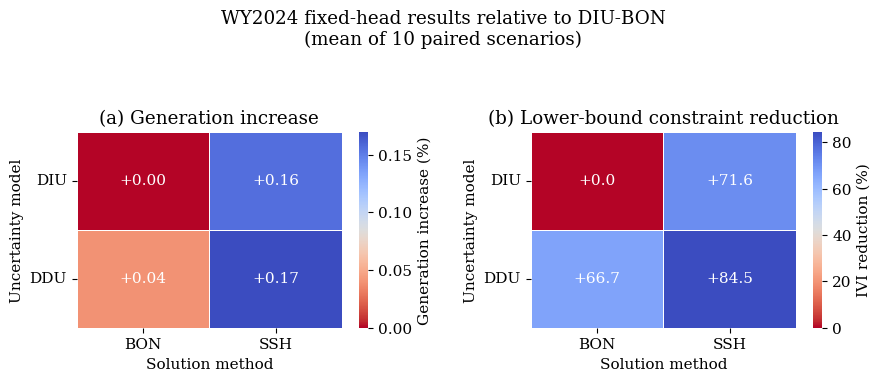

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Full-year fixed-head headline summary
file = (
    "/Users/elizacohn/Desktop/matlab_ddu_four_unit/results/final/paper_sigma/N8760_headline/"
    "summary_N8760_headline.csv"
)

df = pd.read_csv(file)

# Average across the 10 paired scenarios
summary = (
    df.groupby(["policy", "method"])[["energy_MWh", "lower_ivi_kaf"]]
      .mean()
)

# DIU-BON is the baseline
baseline_energy = summary.loc[("DIU", "BON"), "energy_MWh"]
baseline_ivi = summary.loc[("DIU", "BON"), "lower_ivi_kaf"]

policies = ["DIU", "DDU"]
methods = ["BON", "SSH"]

generation = np.zeros((2, 2))
ivi_reduction = np.zeros((2, 2))

for i, policy in enumerate(policies):
    for j, method in enumerate(methods):
        energy = summary.loc[(policy, method), "energy_MWh"]
        ivi = summary.loc[(policy, method), "lower_ivi_kaf"]

        generation[i, j] = 100 * (energy / baseline_energy - 1)
        ivi_reduction[i, j] = 100 * (1 - ivi / baseline_ivi)

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11
})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

sns.heatmap(
    generation,
    ax=axes[0],
    cmap="coolwarm_r",
    vmin=0,
    vmax=generation.max(),
    annot=True,
    fmt="+.2f",
    linewidths=0.5,
    linecolor="white",
    xticklabels=methods,
    yticklabels=policies,
    cbar_kws={"label": "Generation increase (%)"}
)

sns.heatmap(
    ivi_reduction,
    ax=axes[1],
    cmap="coolwarm_r",
    vmin=0,
    vmax=ivi_reduction.max(),
    annot=True,
    fmt="+.1f",
    linewidths=0.5,
    linecolor="white",
    xticklabels=methods,
    yticklabels=policies,
    cbar_kws={"label": "IVI reduction (%)"}
)

axes[0].set_title("(a) Generation increase")
axes[1].set_title("(b) Lower-bound constraint reduction")

for ax in axes:
    ax.set_xlabel("Solution method")
    ax.set_ylabel("Uncertainty model")
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    "WY2024 fixed-head results relative to DIU-BON\n"
    "(mean of 10 paired scenarios)",
    y=1.08
)

plt.tight_layout()
plt.show()

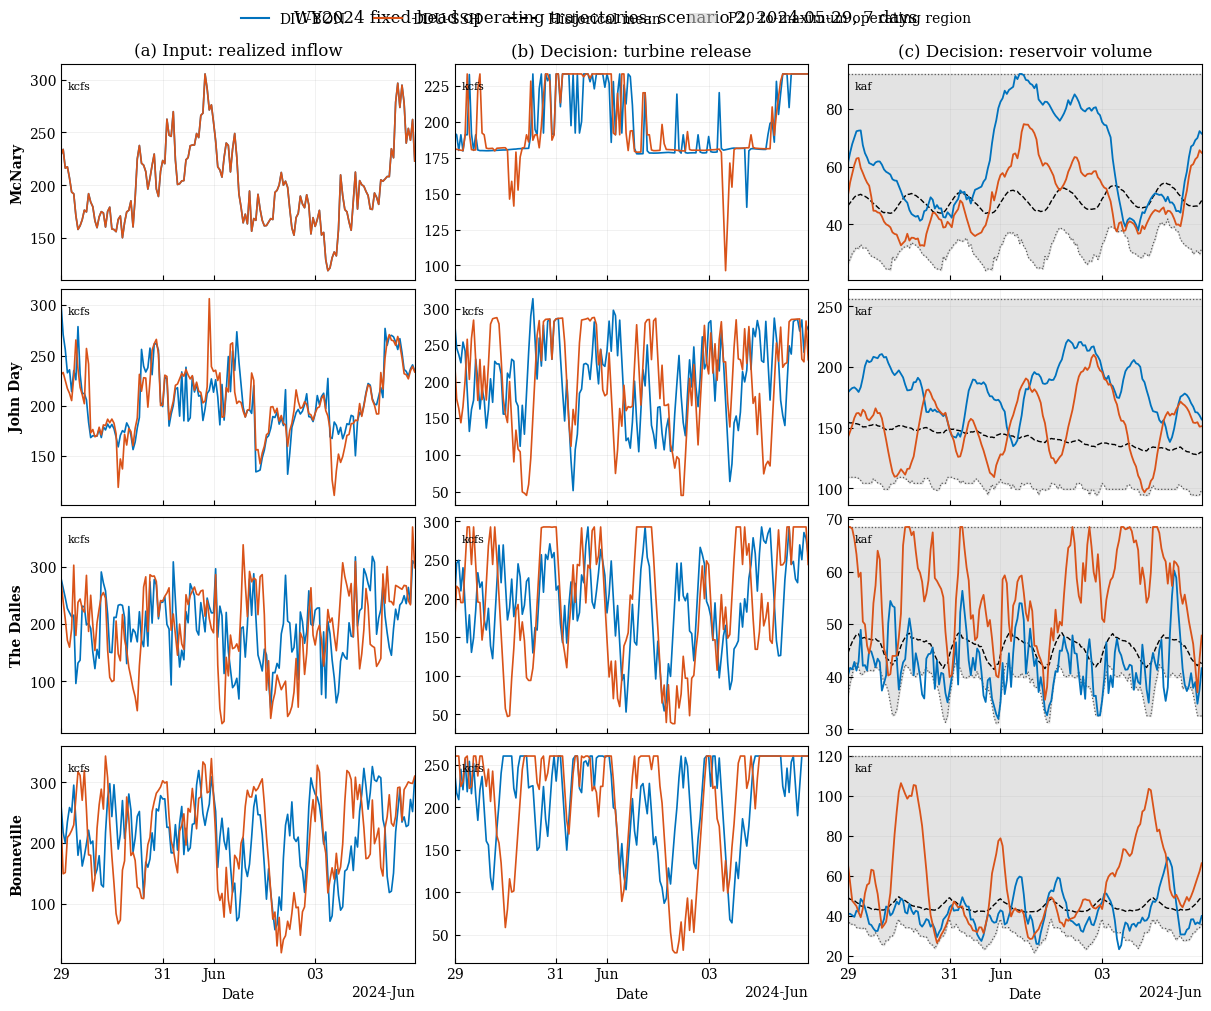

In [20]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.io import loadmat

# -------------------- settings --------------------
scenario = 2
start_date = "2024-05-29"
days = 7

folder = Path("/Users/elizacohn/Desktop/matlab_ddu_four_unit/results/final/paper_sigma/N8760_headline/jobs")
units = ["McNary", "John Day", "The Dalles", "Bonneville"]
codes = ["MCN", "JDA", "TDA", "BON"]
lags = [12, 1, 0, 2]
water_year_start = np.datetime64("2023-10-01T00:00")

# Match the paper
diu_color = "#0072BD"
ddu_color = "#D95319"

# -------------------- load results --------------------
def load_run(policy, method):
    kappa = 0 if policy == "DIU" else 100
    file = folder / f"s{scenario:02d}_e100_{policy}_k{kappa:03d}_{method}.mat"
    return loadmat(file, simplify_cells=True)["traj"]

diu = load_run("DIU", "BON")
ddu = load_run("DDU", "SSH")
inputs = loadmat("/Users/elizacohn/Desktop/matlab_ddu_four_unit/data/inputs.mat", simplify_cells=True)

# -------------------- reconstruct total inflow --------------------
def total_inflow(traj):
    """Realized local inflow plus routed upstream outflow."""
    local = np.asarray(traj["local_real"], float)
    outflow = np.asarray(traj["U"], float) + np.asarray(traj["spill"], float)
    inflow = local.copy()

    # Exogenous routed flow into McNary
    inflow[:, 0] += np.asarray(
        inputs["MCN_2024_routed_exo"]
    ).ravel()[:len(local)]

    # Routed upstream outflow into downstream reservoirs
    for i in range(1, 4):
        upstream = i - 1
        lag = lags[i]

        if lag == 0:
            routed = outflow[:, upstream]
        else:
            initial = np.asarray(
                inputs[f"{codes[upstream]}_2024_out_obs"]
            ).ravel()[0]

            routed = np.r_[
                np.full(lag, initial),
                outflow[:-lag, upstream]
            ]

        inflow[:, i] += routed

    return inflow

diu_inflow = total_inflow(diu)
ddu_inflow = total_inflow(ddu)

# -------------------- select plotting window --------------------
start = int(
    (np.datetime64(start_date) - water_year_start)
    / np.timedelta64(1, "h")
)

stop = start + days * 24
sl = slice(start, stop)

dates = (
    water_year_start
    + np.arange(start, stop).astype("timedelta64[h]")
)

# -------------------- plot --------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.linewidth": 0.8
})

fig, axes = plt.subplots(
    4, 3,
    figsize=(12, 10),
    sharex=True,
    constrained_layout=True
)

axes[0, 0].set_title("(a) Input: realized inflow")
axes[0, 1].set_title("(b) Decision: turbine release")
axes[0, 2].set_title("(c) Decision: reservoir volume")

for i, unit in enumerate(units):

    # 1. Realized total inflow
    axes[i, 0].plot(
        dates, diu_inflow[sl, i],
        color=diu_color, linewidth=1.2
    )
    axes[i, 0].plot(
        dates, ddu_inflow[sl, i],
        color=ddu_color, linewidth=1.2
    )

    # 2. Turbine-release decision
    axes[i, 1].plot(
        dates, diu["U"][sl, i],
        color=diu_color, linewidth=1.2
    )
    axes[i, 1].plot(
        dates, ddu["U"][sl, i],
        color=ddu_color, linewidth=1.2
    )

    # 3. P20-to-maximum operating region
    p20 = diu["qLow"][sl, i]
    maximum = diu["qHigh"][sl, i]
    mean = diu["ref"][sl, i]

    axes[i, 2].fill_between(
        dates,
        p20,
        maximum,
        color="0.80",
        alpha=0.55
    )

    # Historical mean and operating boundaries
    axes[i, 2].plot(
        dates, mean,
        color="black",
        linestyle="--",
        linewidth=1.0
    )
    axes[i, 2].plot(
        dates, p20,
        color="0.35",
        linestyle=":",
        linewidth=0.9
    )
    axes[i, 2].plot(
        dates, maximum,
        color="0.35",
        linestyle=":",
        linewidth=0.9
    )

    # Volume decisions
    axes[i, 2].plot(
        dates, diu["V"][sl, i],
        color=diu_color,
        linewidth=1.3
    )
    axes[i, 2].plot(
        dates, ddu["V"][sl, i],
        color=ddu_color,
        linewidth=1.3
    )

    axes[i, 0].set_ylabel(unit, fontweight="bold")

    for ax in axes[i]:
        ax.grid(alpha=0.25, linewidth=0.5)
        ax.margins(x=0)
        ax.tick_params(direction="in")

# Units
for ax in axes[:, 0]:
    ax.text(
        0.02, 0.92, "kcfs",
        transform=ax.transAxes,
        va="top",
        fontsize=8
    )

for ax in axes[:, 1]:
    ax.text(
        0.02, 0.92, "kcfs",
        transform=ax.transAxes,
        va="top",
        fontsize=8
    )

for ax in axes[:, 2]:
    ax.text(
        0.02, 0.92, "kaf",
        transform=ax.transAxes,
        va="top",
        fontsize=8
    )

# Date formatting
locator = mdates.AutoDateLocator(minticks=3, maxticks=5)

for ax in axes[-1]:
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(
        mdates.ConciseDateFormatter(locator)
    )
    ax.set_xlabel("Date")

# Common legend
legend = [
    Line2D(
        [0], [0],
        color=diu_color,
        linewidth=1.5,
        label="DIU-BON"
    ),
    Line2D(
        [0], [0],
        color=ddu_color,
        linewidth=1.5,
        label="DDU-SSH"
    ),
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        label="Historical mean"
    ),
    Patch(
        facecolor="0.80",
        alpha=0.55,
        label="P20-to-maximum operating region"
    )
]

fig.legend(
    handles=legend,
    loc="outside upper center",
    ncol=4,
    frameon=False
)

fig.suptitle(
    f"WY2024 fixed-head operating trajectories: "
    f"scenario {scenario}, {start_date}, {days} days",
    fontsize=12
)

plt.show()

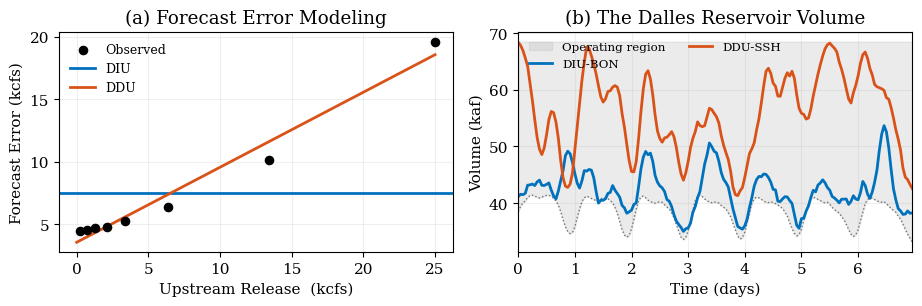

In [30]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.linewidth": 0.8
})

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))

# -------------------- (a) uncertainty model --------------------
axes[0].scatter(
    ramp_bins,
    error_sd,
    color="black",
    s=35,
    zorder=3,
    label="Observed"
)

axes[0].axhline(
    diu_sd,
    color=blue,
    linewidth=2,
    label="DIU"
)

axes[0].plot(
    xfit,
    ddu_sd,
    color=orange,
    linewidth=2,
    label="DDU"
)

axes[0].set_title("(a) Forecast Error Modeling")
axes[0].set_xlabel(r"Upstream Release  (kcfs)")
axes[0].set_ylabel("Forecast Error (kcfs)")
axes[0].grid(alpha=0.2)
axes[0].legend(frameon=False, fontsize=9)

# -------------------- (b) storage protection --------------------
time_days = np.arange(len(volume_diu)) / 24

axes[1].fill_between(
    time_days,
    p20,
    maximum,
    color="0.75",
    alpha=0.30,
    label="Operating region"
)

axes[1].plot(
    time_days,
    p20,
    color="0.45",
    linestyle=":",
    linewidth=1
)

axes[1].plot(
    time_days,
    volume_diu,
    color=blue,
    linewidth=2,
    label="DIU-BON"
)

axes[1].plot(
    time_days,
    volume_ddu,
    color=orange,
    linewidth=2,
    label="DDU-SSH"
)

axes[1].set_title("(b) The Dalles Reservoir Volume")
axes[1].set_xlabel("Time (days)")
axes[1].set_ylabel("Volume (kaf)")
axes[1].grid(alpha=0.2)
axes[1].margins(x=0)

axes[1].legend(
    frameon=False,
    fontsize=8.5,
    ncol=2,
    loc="upper left"
)

plt.tight_layout()
plt.show()